# Monday: Python and 2D rotations

Rotate a point attached to a quadcopter. On Wednesday, use the same rotation to simulate motion.

Before each example, predict the result with a neighbor. Run it, change an input, and check the result.

| Minutes | Topic |
|---|---|
| 0–5 | Purpose and execution |
| 5–15 | Imports, variables, containers |
| 15–25 | Functions and rotation |
| 25–35 | Conditionals and for loops |
| 35–45 | While loops and state |
| 45–50 | Plots and debugging |
| 50–75 | Independent challenge; no AI |

Choose `.venv` as your VS Code kernel. Run cells in order; variables persist until you restart the kernel. Use Restart and Run All to check your work. All exercises are in class.

## 5–15 min: imports and variables

A module contains reusable Python code. A library can contain several modules. Installing adds a package to your environment; importing makes it available to your program. `as np` gives NumPy a short name.

Python finds modules through `sys.path`, including installed packages. Avoid naming your files `numpy.py` or `matplotlib.py`.

Predict the type of each variable below.

In [54]:
import numpy as np
import matplotlib.pyplot as plt

x = 2.0                 # float, meters
y = 3.0
samples = 6             # int
vehicle_name = "Quad A" # str
armed = False           # bool
position = np.array([x, y])
print(position, type(x), type(samples), type(vehicle_name), type(armed))

[2. 3.] <class 'float'> <class 'int'> <class 'str'> <class 'bool'>


Lists store sequences. Tuples are immutable sequences. NumPy arrays support numerical operations.

Indexing starts at zero: `[-1]` gets the last item; `[0:2]` gets indices 0 and 1.

Predict what multiplying a list and an array by 2 will do. Change the second coordinate and check each container's length.

In [55]:
position_list = [2.0, 3.0]
waypoint = (2.0, 3.0)
print(position_list * 2)
print(position * 2)
print(waypoint[0], position[-1], position[0:2], len(position))

[2.0, 3.0, 2.0, 3.0]
[4. 6.]
2.0 3.0 [2. 3.] 2


## 15–25 min: functions

`def` defines a function. Parameters are names in the definition; arguments are values passed to it. Indentation marks the body. Local variables belong to the function call.

`return` ends the call and sends a value back. `print` displays a value. A function without `return` returns `None`.

Predict the conversion of 180°. Try 90° and compare with `np.pi / 2`.

In [56]:
def degrees_to_radians(angle_deg:float) -> float:
    angle_rad:float = angle_deg * np.pi / 180.0
    return angle_rad

heading:float = degrees_to_radians(180)
print(heading)

3.141592653589793


In [57]:
def display_heading(angle_deg):
    print(degrees_to_radians(angle_deg))

result = display_heading(90)
print("Returned:", result)  # Why None?

1.5707963267948966
Returned: None


### Coordinates and units

“Move forward” depends on which way the robot faces. At yaw 0°, forward is east; at yaw 90°, forward is north. A velocity of `[1, 0]` needs a **frame** and **units** to have meaning.

| Quantity | Convention |
|---|---|
| World axes | X east/right, Y north/up |
| Body axes | X forward, Y left |
| Yaw | Counterclockwise from world X to body X |
| Units | Position m, velocity m/s, time s, yaw rad, yaw rate rad/s |

#### The full problem: express a point in another frame

A sensor reports a point relative to the robot. Where is that same point in the world?

For two rigid Cartesian frames using the same units, the general transformation is:

$$\boxed{p^{A}=R^{A}_{B}p^{B}+t^{A}_{B}}.$$

Read the **superscript as the destination frame** and the **subscript as the source frame**: $R^{A}_{B}$ converts B-frame components to A-frame components. $t^{A}_{B}$ is the B origin's position measured in A. The superscript on $p^{A}$ says which frame its coordinates use; it is a frame label, not a power. The point itself has not moved; its coordinates change.

For body B and world W:

$$\boxed{p^{W}=R^{W}_{B}p^{B}+t^{W}_{B}}.$$

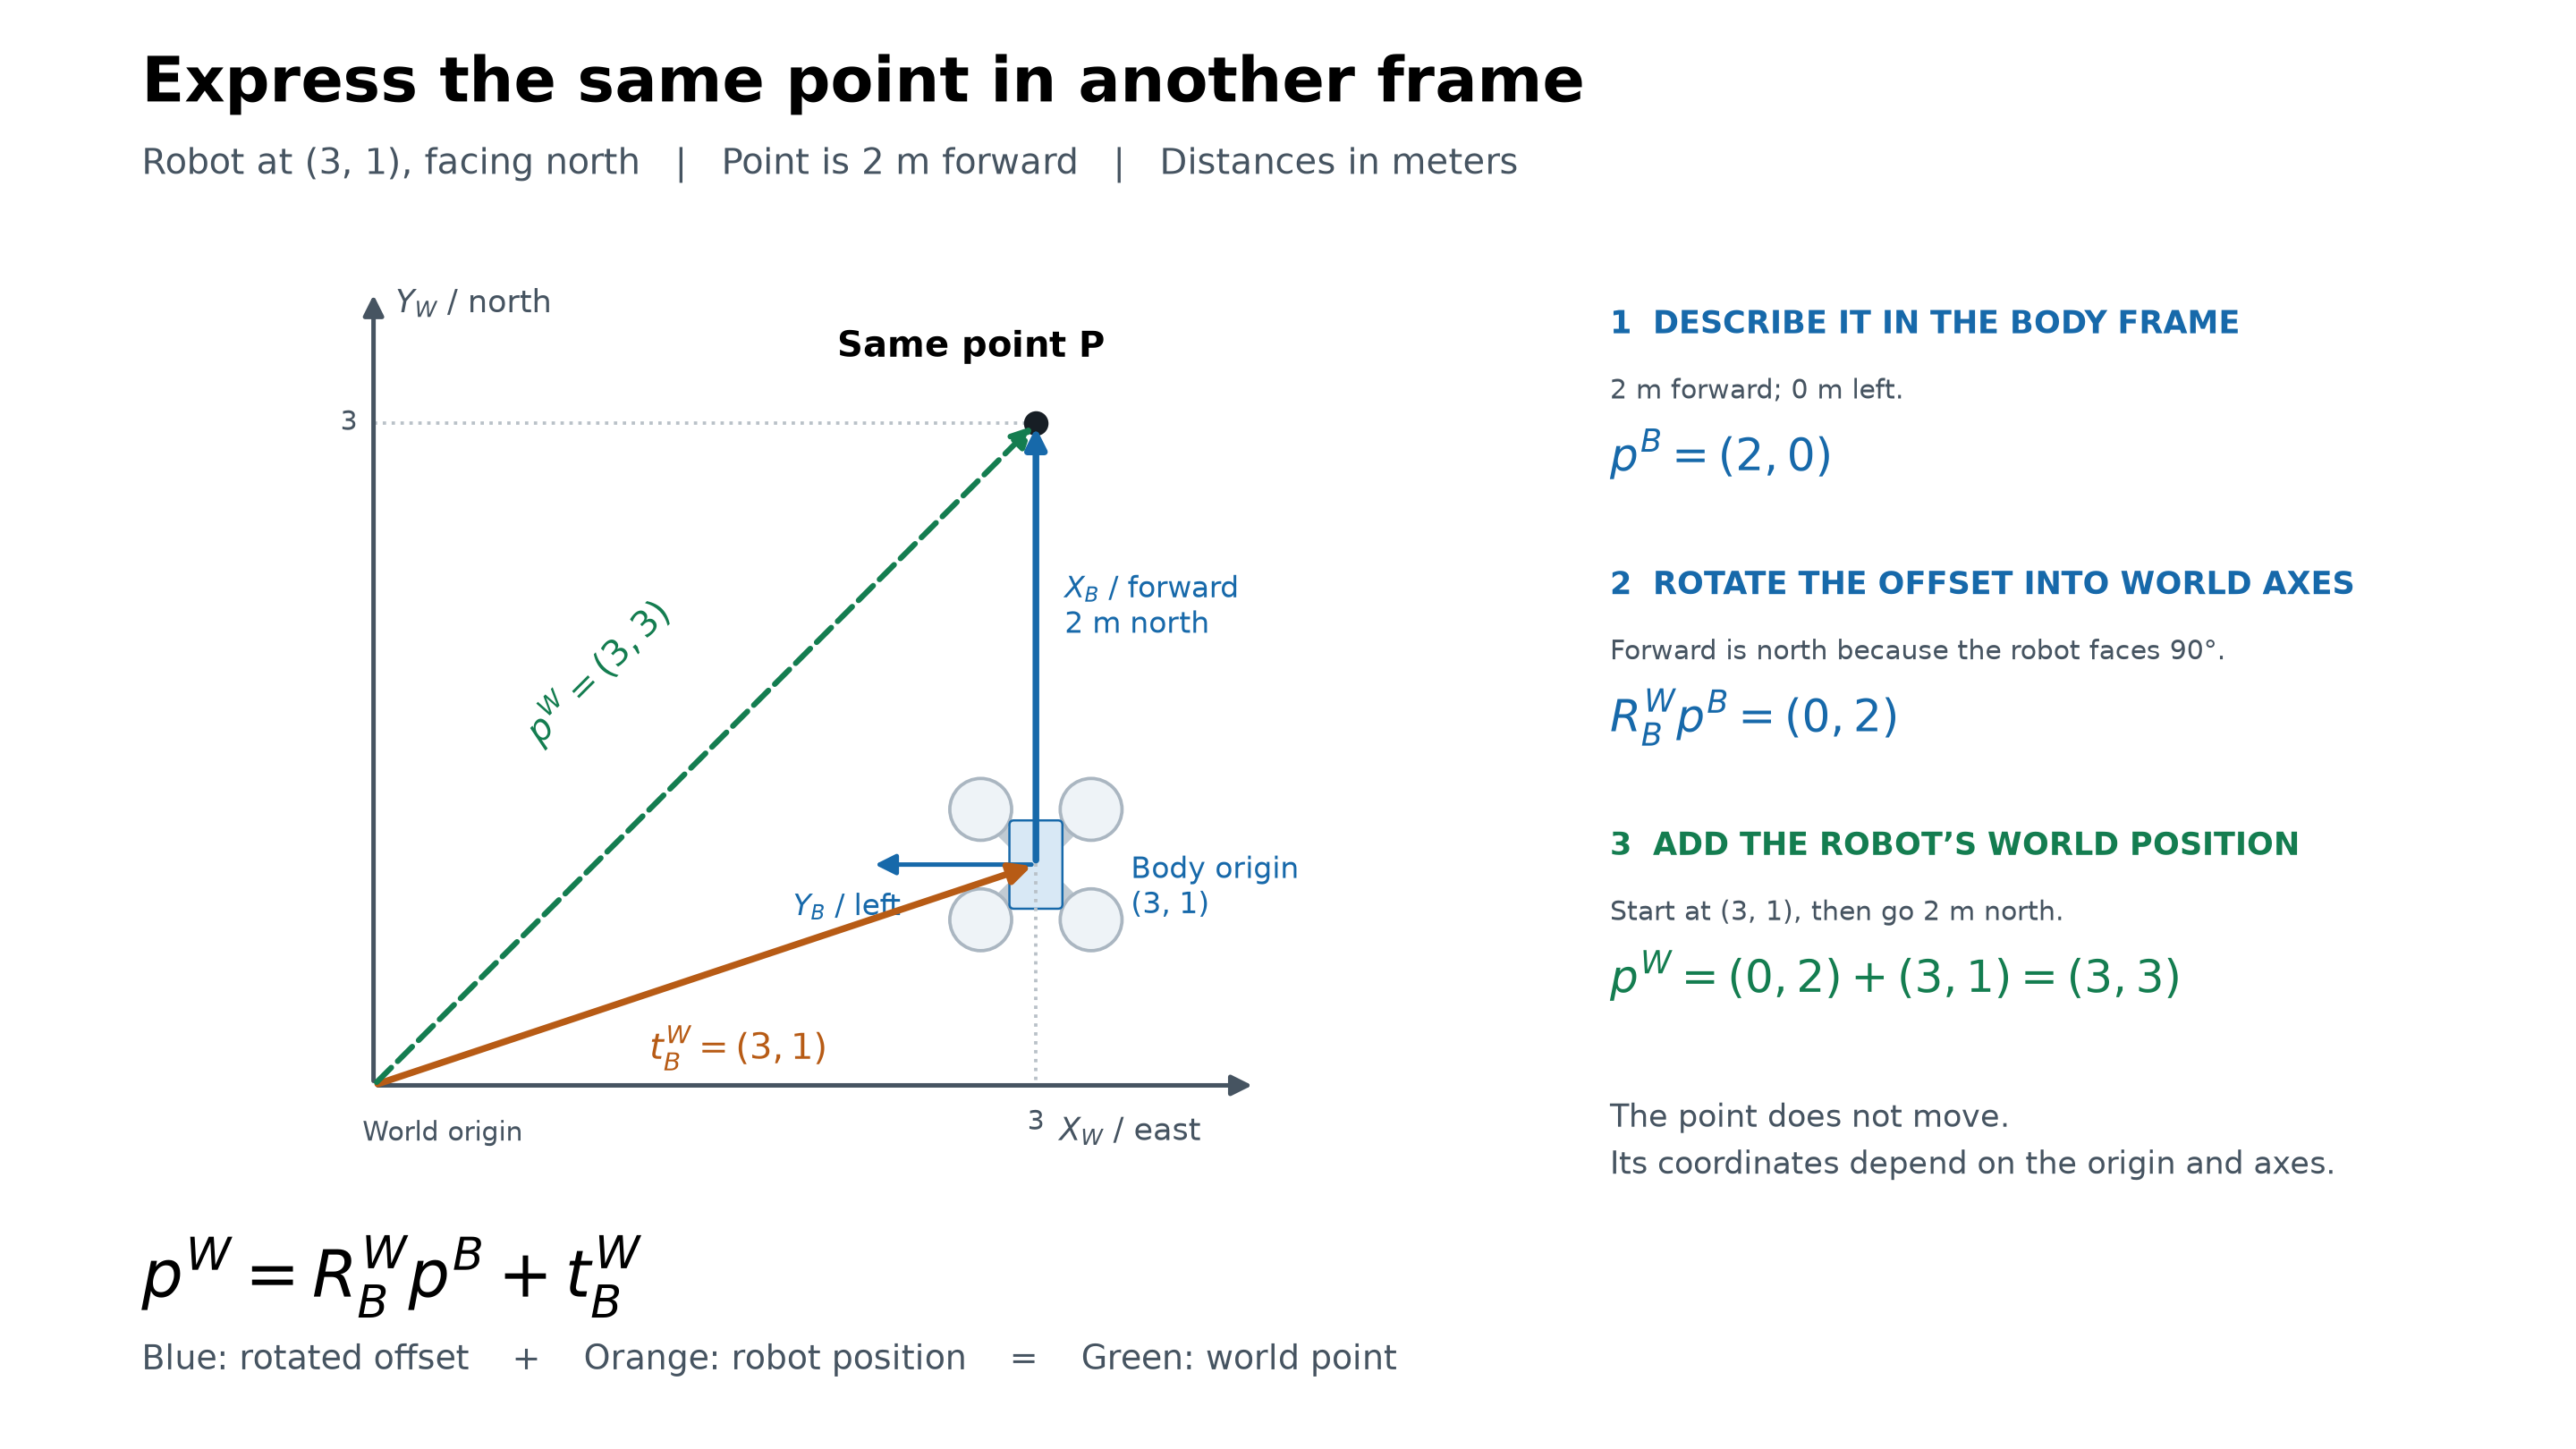

| Term | Meaning |
|---|---|
| $p^{B}$ | Point coordinates measured from the robot, along its body axes |
| $R^{W}_{B}$ | Body-to-world rotation matrix |
| $t^{W}_{B}$ | Robot origin's position in world coordinates |
| $p^{W}$ | The same point's world coordinates |

**Start at the robot's world position, then add the point's offset expressed along the world axes.** A rotation matrix provides that change of direction: its columns are the body unit axes expressed in the world frame.

In 2D, using column vectors:

$$\begin{bmatrix}x_W\\y_W\end{bmatrix}
=\underbrace{\begin{bmatrix}\cos\theta&-\sin\theta\\\sin\theta&\cos\theta\end{bmatrix}}_{R^{W}_{B}}
\begin{bmatrix}x_B\\y_B\end{bmatrix}
+\underbrace{\begin{bmatrix}x_{robot}\\y_{robot}\end{bmatrix}}_{t^{W}_{B}}.$$

Example: the robot is at (3, 1), facing north. A point is 2 m forward:

$$p^{W}=\begin{bmatrix}0&-1\\1&0\end{bmatrix}\begin{bmatrix}2\\0\end{bmatrix}
+\begin{bmatrix}3\\1\end{bmatrix}
=\begin{bmatrix}0\\2\end{bmatrix}+\begin{bmatrix}3\\1\end{bmatrix}
=\begin{bmatrix}3\\3\end{bmatrix}.$$

**Transformation** includes rotation and translation. **Translation** means shifting the origin. We transform coordinates between frames, not one physical point into a different point.

Monday's core exercise puts the robot at the world origin: $t^{W}_{B}=0$, so $p^{W}=R^{W}_{B}p^{B}$. We write this rotation as $R(\theta)$ below. Now derive its entries from the axes.

When the robot later turns with a point attached, $p^{B}$ stays fixed while $R^{W}_{B}$ changes, so that point physically moves in the world. This differs from describing one fixed pose in two frames.

#### 1. Find the rotated axes

A unit vector has length 1. The blue arrow is one unit forward; orange is one unit left. Dashed lines show their world X and Y components.

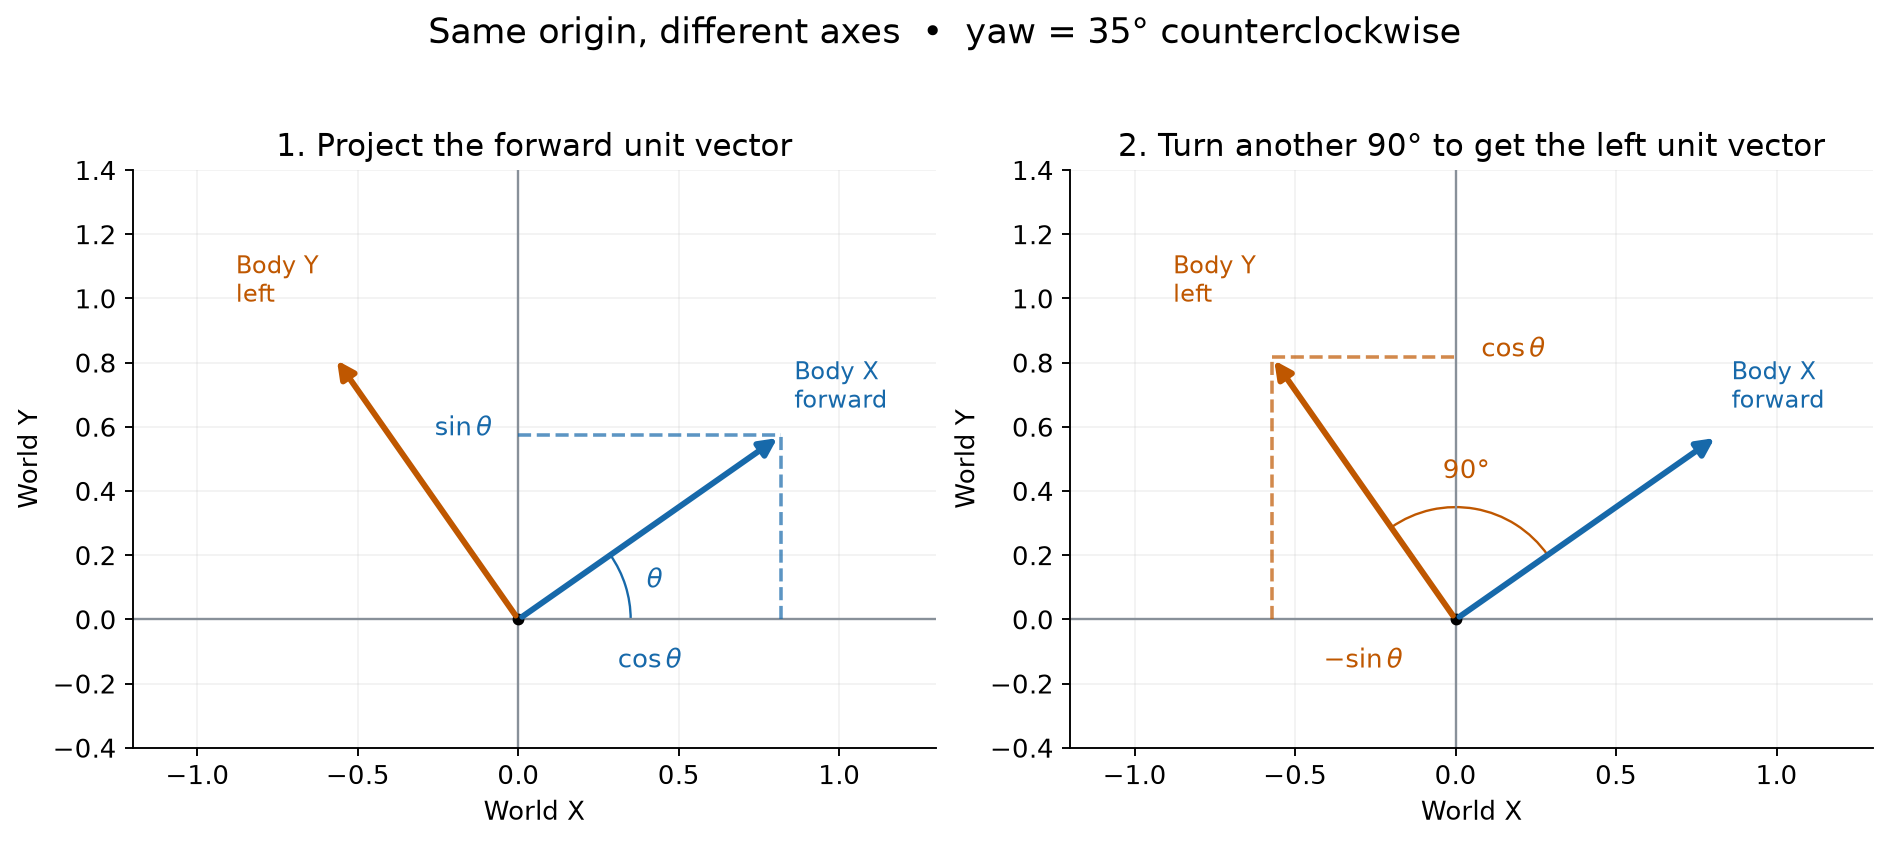

The forward arrow makes angle $\theta$ with world X. From a unit right triangle, adjacent = $\cos\theta$ and opposite = $\sin\theta$:

$$\hat{x}_B^{\,W}=\begin{bmatrix}\cos\theta\\\sin\theta\end{bmatrix}.$$

The left arrow is another 90° counterclockwise:

$$\hat{y}_B^{\,W}
=\begin{bmatrix}\cos(\theta+\pi/2)\\\sin(\theta+\pi/2)\end{bmatrix}
=\begin{bmatrix}-\sin\theta\\\cos\theta\end{bmatrix}.$$

The superscript $W$ means “expressed in world coordinates.” At the angle shown, the left arrow points partly west, so its X component is negative. These formulas also work outside the first quadrant.

**Predict:** at yaw 90°, where do the forward and left arrows point?

#### 2. Put those arrows in the matrix columns

A body point $[x_B,y_B]^T$ means “$x_B$ units forward, then $y_B$ units left.” Scale the two arrows and add:

$$p^{W}=x_B\hat{x}_B^{\,W}+y_B\hat{y}_B^{\,W}
=\begin{bmatrix}x_B\cos\theta-y_B\sin\theta\\x_B\sin\theta+y_B\cos\theta\end{bmatrix}.$$

Matrix multiplication writes the same sum compactly:

$$p^{W}=\underbrace{\begin{bmatrix}\cos\theta&-\sin\theta\\\sin\theta&\cos\theta\end{bmatrix}}_{R(\theta)}\begin{bmatrix}x_B\\y_B\end{bmatrix}.$$

**Column 1 is body-forward in world coordinates. Column 2 is body-left in world coordinates.** Each row computes one world coordinate.

At 90°:

$$R(\pi/2)=\begin{bmatrix}0&-1\\1&0\end{bmatrix}.$$

Read its columns: forward becomes north; left becomes west. At 0°, the axes align and $R(0)$ is the identity matrix.

#### 3. Rotate a point; add the origin if needed

For $p^{B}=[2,1]^T$, add twice the forward arrow and once the left arrow. The green arrow is the result.

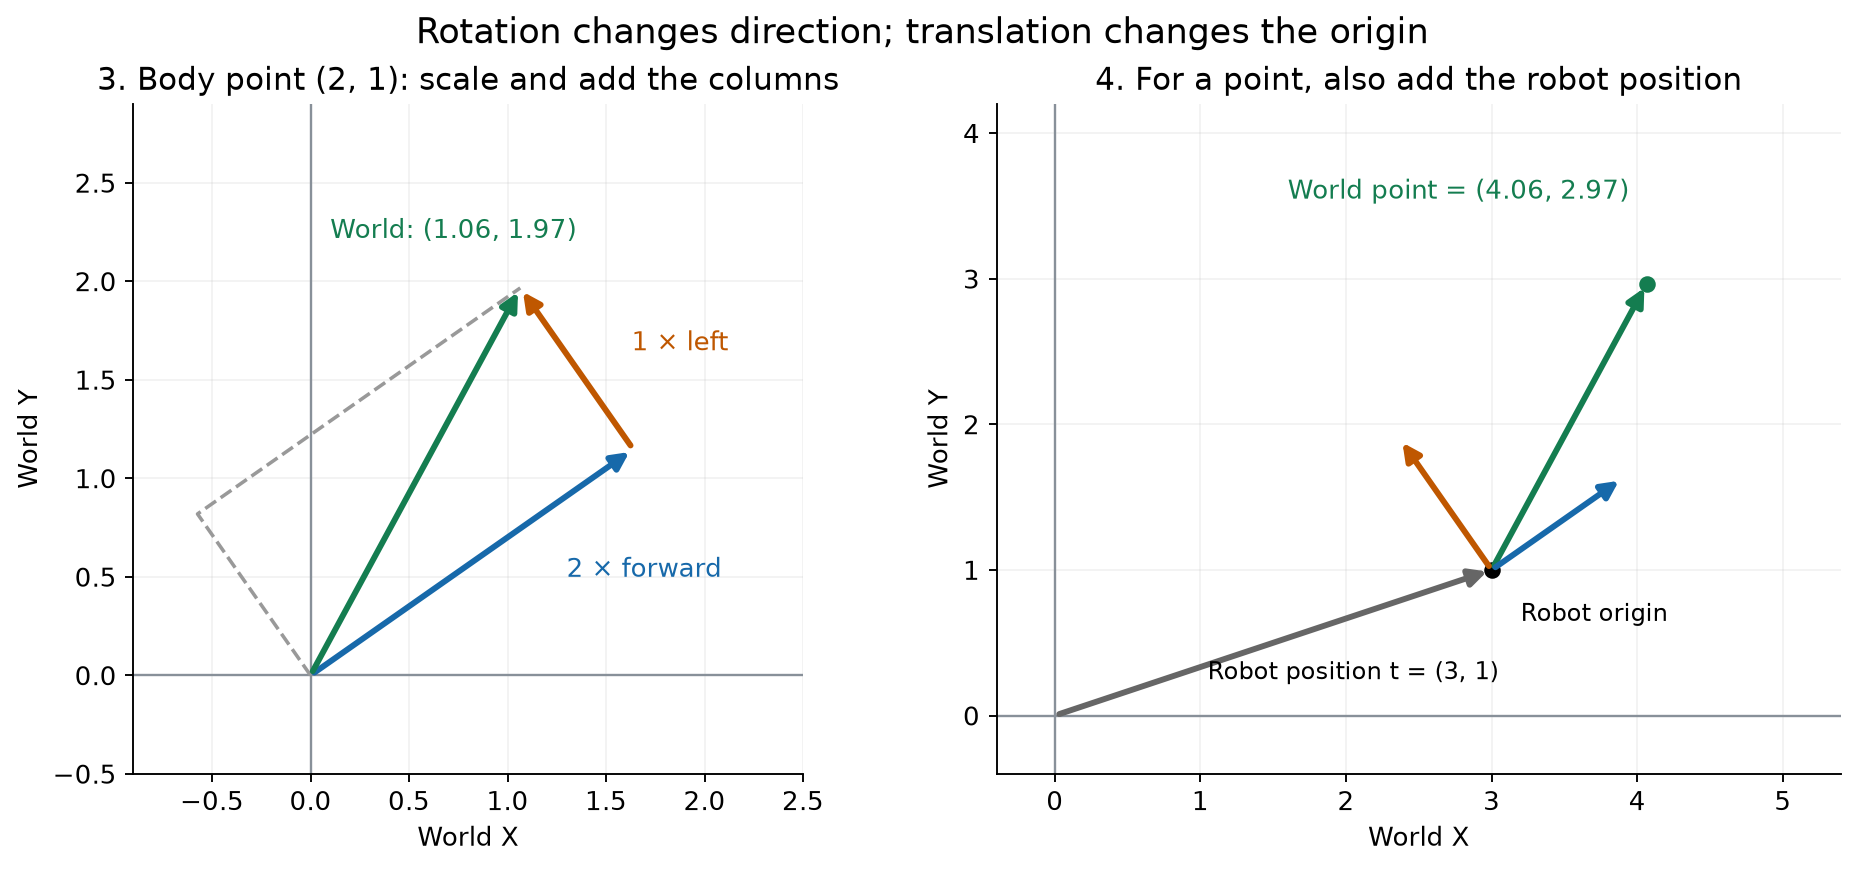

The left panel has a shared origin. In the right panel, the robot is at world position $t^{W}_{B}=[3,1]^T$:

$$p^{W}=t^{W}_{B}+R(\theta)p^{B}.$$

Rotation gives the offset from the robot; translation places that offset in the world. These are coordinates of the **same point**, measured in different frames.

For the robot's translational velocity, use $v^{W}=R(\theta)v^{B}$ without adding position. Adding meters to meters per second would mix units. This velocity equation describes the robot center; a point on a spinning robot has an additional rotational velocity.

Rotation preserves length because its two unit columns stay perpendicular. To convert a world vector back to body coordinates, undo the rotation:

$$R^{-1}(\theta)=R(-\theta)=R(\theta)^T.$$

For a world **point**, subtract the robot position first: $p^{B}=(R^{W}_{B})^T(p^{W}-t^{W}_{B})$.

#### 4. Why radians matter

Radians measure angle as arc length divided by radius: $\theta=s/r$. A full circle is $2\pi$ rad, so:

$$\theta_{rad}=\theta_{deg}\frac{\pi}{180},\qquad 90^\circ=\pi/2\text{ rad}.$$

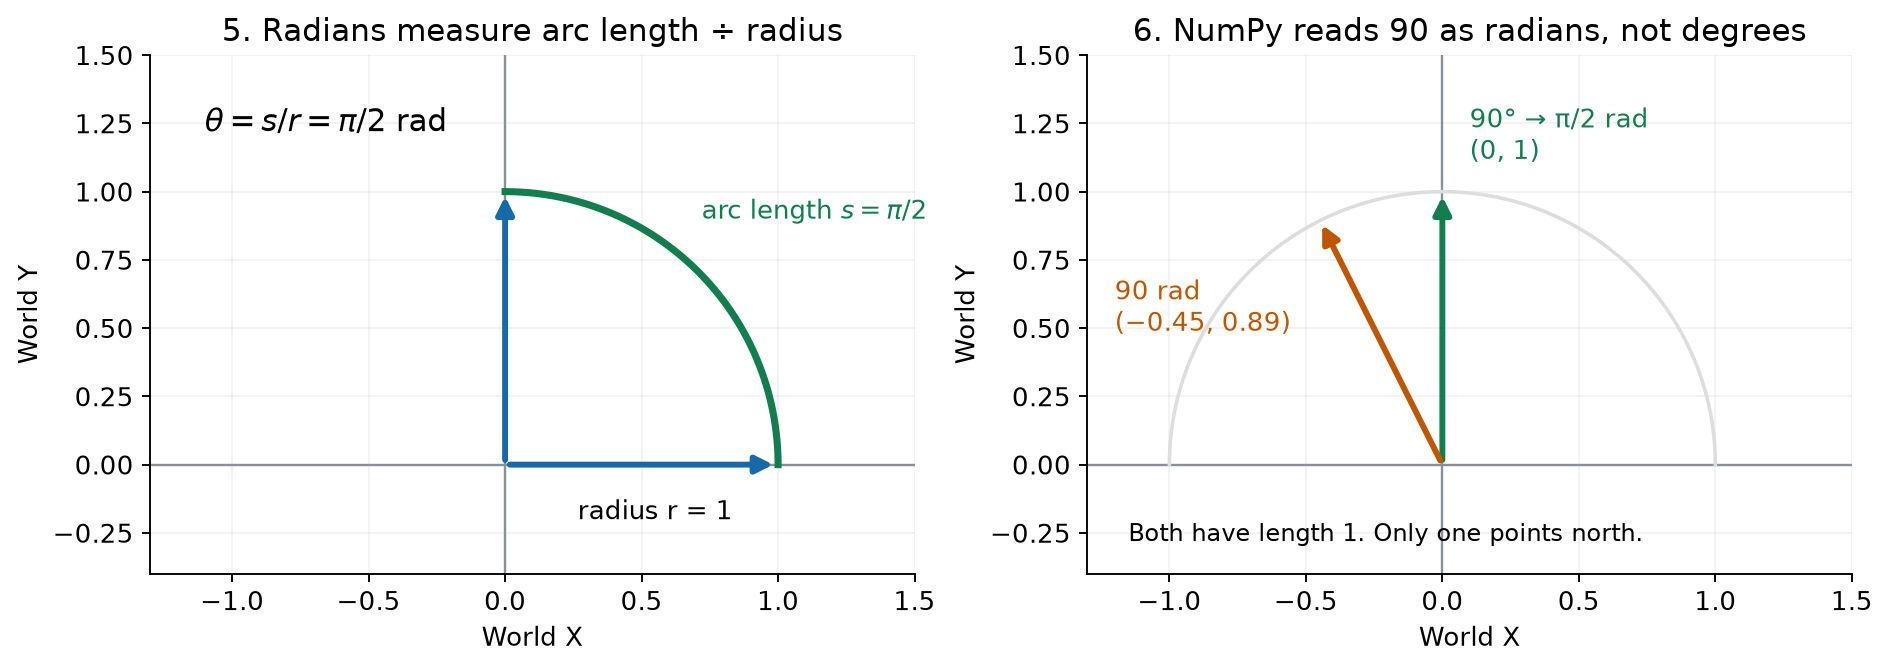

NumPy's sine and cosine expect radians. `np.cos(90)` means 90 **radians**, not 90°. Convert with `np.deg2rad(90)` first. Both arrows above have length 1, so a length check alone cannot catch a unit error; also check known headings.

**Try it:** change `heading_deg` below to 0, 90, or −90. Predict the arrow directions first. Change `body_point` to `[1.0, 0.0]` or `[0.0, 1.0]` to isolate a matrix column. This computes the weighted sum directly; the next function packages it as a matrix.

World point: [1.065 1.966]


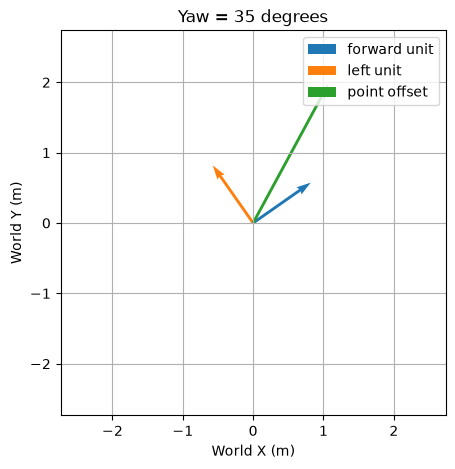

In [58]:
heading_deg = 35
body_point = np.array([2.0, 1.0])
angle_rad = np.deg2rad(heading_deg)
forward_world = np.array([np.cos(angle_rad), np.sin(angle_rad)])
left_world = np.array([-np.sin(angle_rad), np.cos(angle_rad)])
world_point = body_point[0] * forward_world + body_point[1] * left_world
print("World point:", np.round(world_point, 3))

fig, ax = plt.subplots(figsize=(5, 5))
for vector, color, label in [(forward_world, "tab:blue", "forward unit"),
                              (left_world, "tab:orange", "left unit"),
                              (world_point, "tab:green", "point offset")]:
    ax.quiver(0, 0, *vector, angles="xy", scale_units="xy", scale=1,
              color=color, label=label)
limit = max(1.0, np.linalg.norm(body_point)) + 0.5
ax.set(xlim=(-limit, limit), ylim=(-limit, limit),
       xlabel="World X (m)", ylabel="World Y (m)", title=f"Yaw = {heading_deg} degrees")
ax.set_aspect("equal")
ax.grid(True)
ax.legend()
plt.show()


**Check your understanding:** why is the minus sign in the second column? Why does a leftward body command point west at yaw 90°?

Now predict sine and cosine at 90° before running the next cell.

In [59]:
theta = np.deg2rad(90)
c = np.cos(theta)
s = np.sin(theta)
print(c, s)  # Floating-point numbers are approximate.

6.123233995736766e-17 1.0


Put the calculation in a function. Its `c` and `s` are local variables; they do not change the variables above.

In [ ]:
def rotation_matrix(theta):
    c = np.cos(theta)
    s = np.sin(theta)
    return np.array([[c, -s], [s, c]])

R = rotation_matrix(np.deg2rad(45))
point_body = np.array([2.0, 0.0])
point_world = R @ point_body 
# another way to multiply is np.dot(R, point_body)
point_world_dot = np.dot(R, point_body)
# can also do matrix multiplication using np.matmul
point_world_matmul = np.matmul(R, point_body)
print("point_world", point_world)
print("point_world_dot", point_world_dot)
print("point_world_matmul", point_world_matmul)

[1.41421356 1.41421356]


`@` multiplies matrices; `*` multiplies array elements and may broadcast shapes. Predict the output shapes. Try a 90° heading and check the result with `np.allclose`.

In [61]:
print((R @ point_body).shape)
print((R * point_body).shape)
print(np.allclose(rotation_matrix(np.pi / 2) @ point_body, [0, 2]))

(2,)
(2, 2)
True


### Optional: add a sensor frame

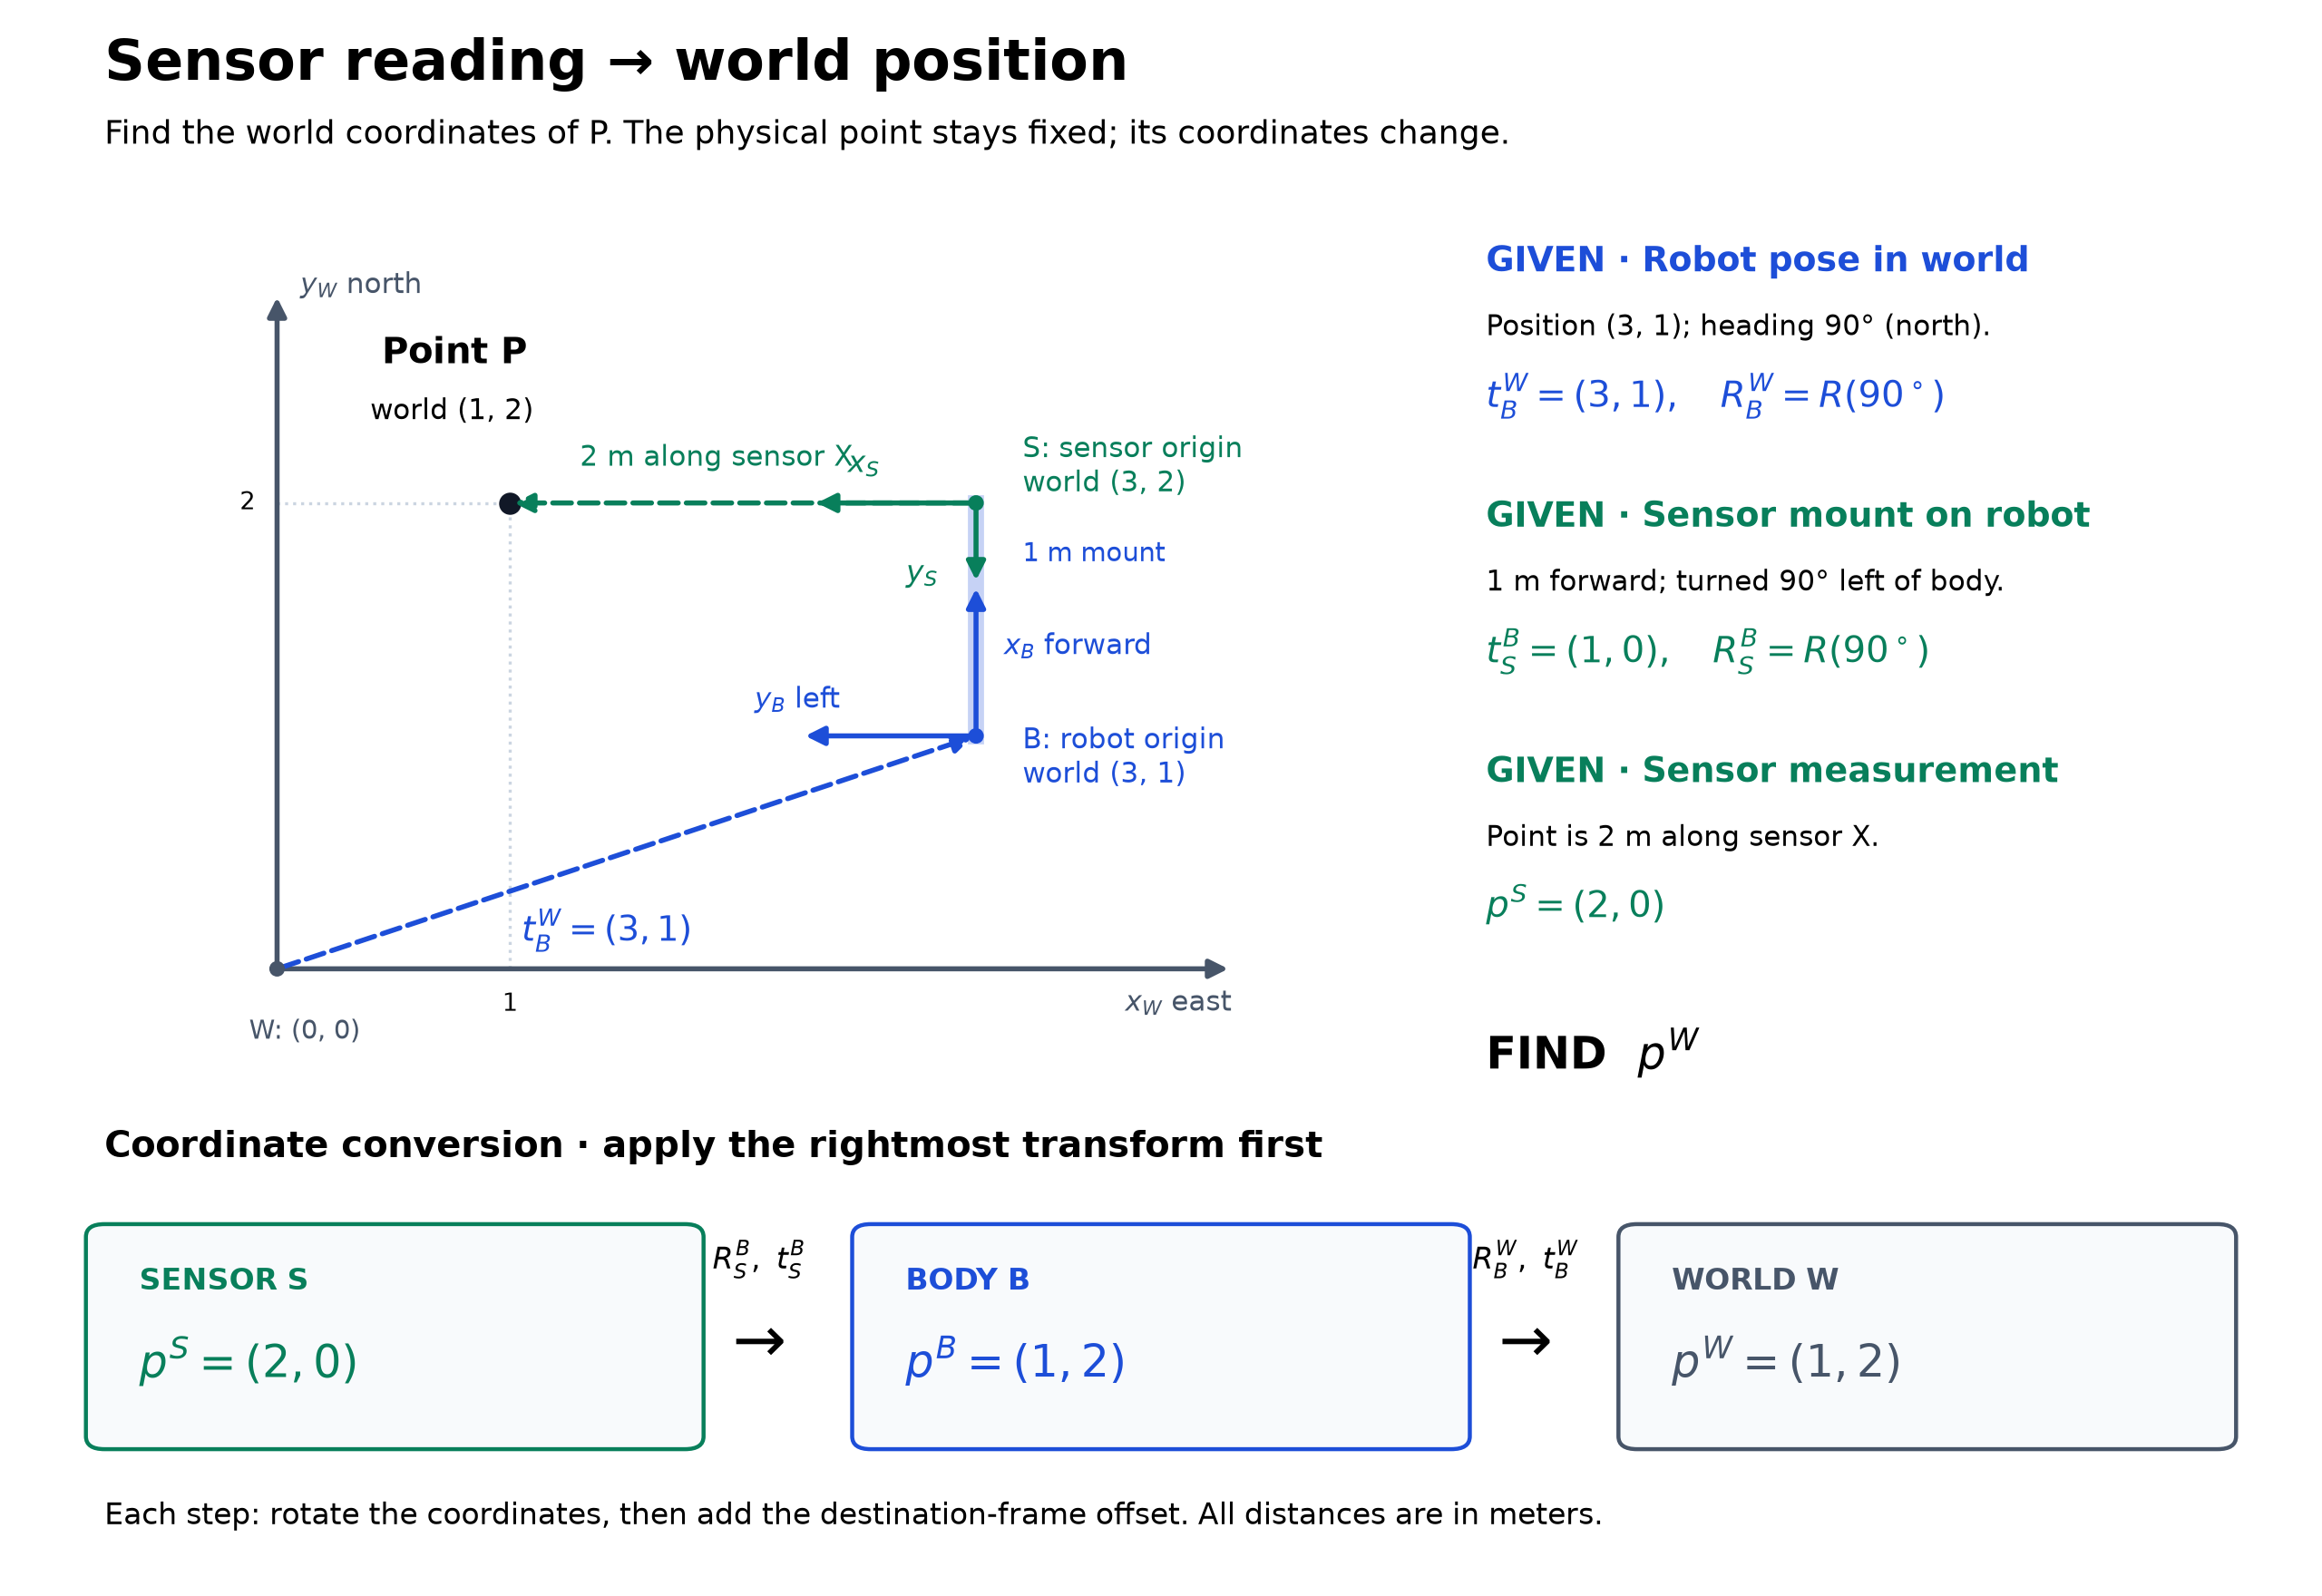

A second link means adding another **frame**, not another point. A sensor mounted on the robot measures $p^{S}$. Convert the same point from sensor S to body B, then from body B to world W:

$$\text{Sensor S}\xrightarrow{R^{B}_{S},\;t^{B}_{S}}\text{Body B}\xrightarrow{R^{W}_{B},\;t^{W}_{B}}\text{World W}.$$

$$p^{B}=R^{B}_{S}p^{S}+t^{B}_{S},\qquad p^{W}=R^{W}_{B}p^{B}+t^{W}_{B}.$$

The rotation chain follows the same notation:

$$\boxed{R^{W}_{S}=R^{W}_{B}R^{B}_{S}}.$$

Read right to left: S → B, then B → W. The shared B labels identify the intermediate frame. With numbered frames W = 0, B = 1, S = 2, this is $R^{0}_{2}=R^{0}_{1}R^{1}_{2}$.

Substitute the first equation into the second:

$$p^{W}=R^{W}_{B}(R^{B}_{S}p^{S}+t^{B}_{S})+t^{W}_{B}
=\underbrace{R^{W}_{B}R^{B}_{S}}_{R^{W}_{S}}p^{S}
+\underbrace{(R^{W}_{B}t^{B}_{S}+t^{W}_{B})}_{t^{W}_{S}}.$$

Apply the sensor-to-body transform first. Rotate the sensor's mounting offset into world coordinates **before** adding the robot position; the two offsets start in different frames.

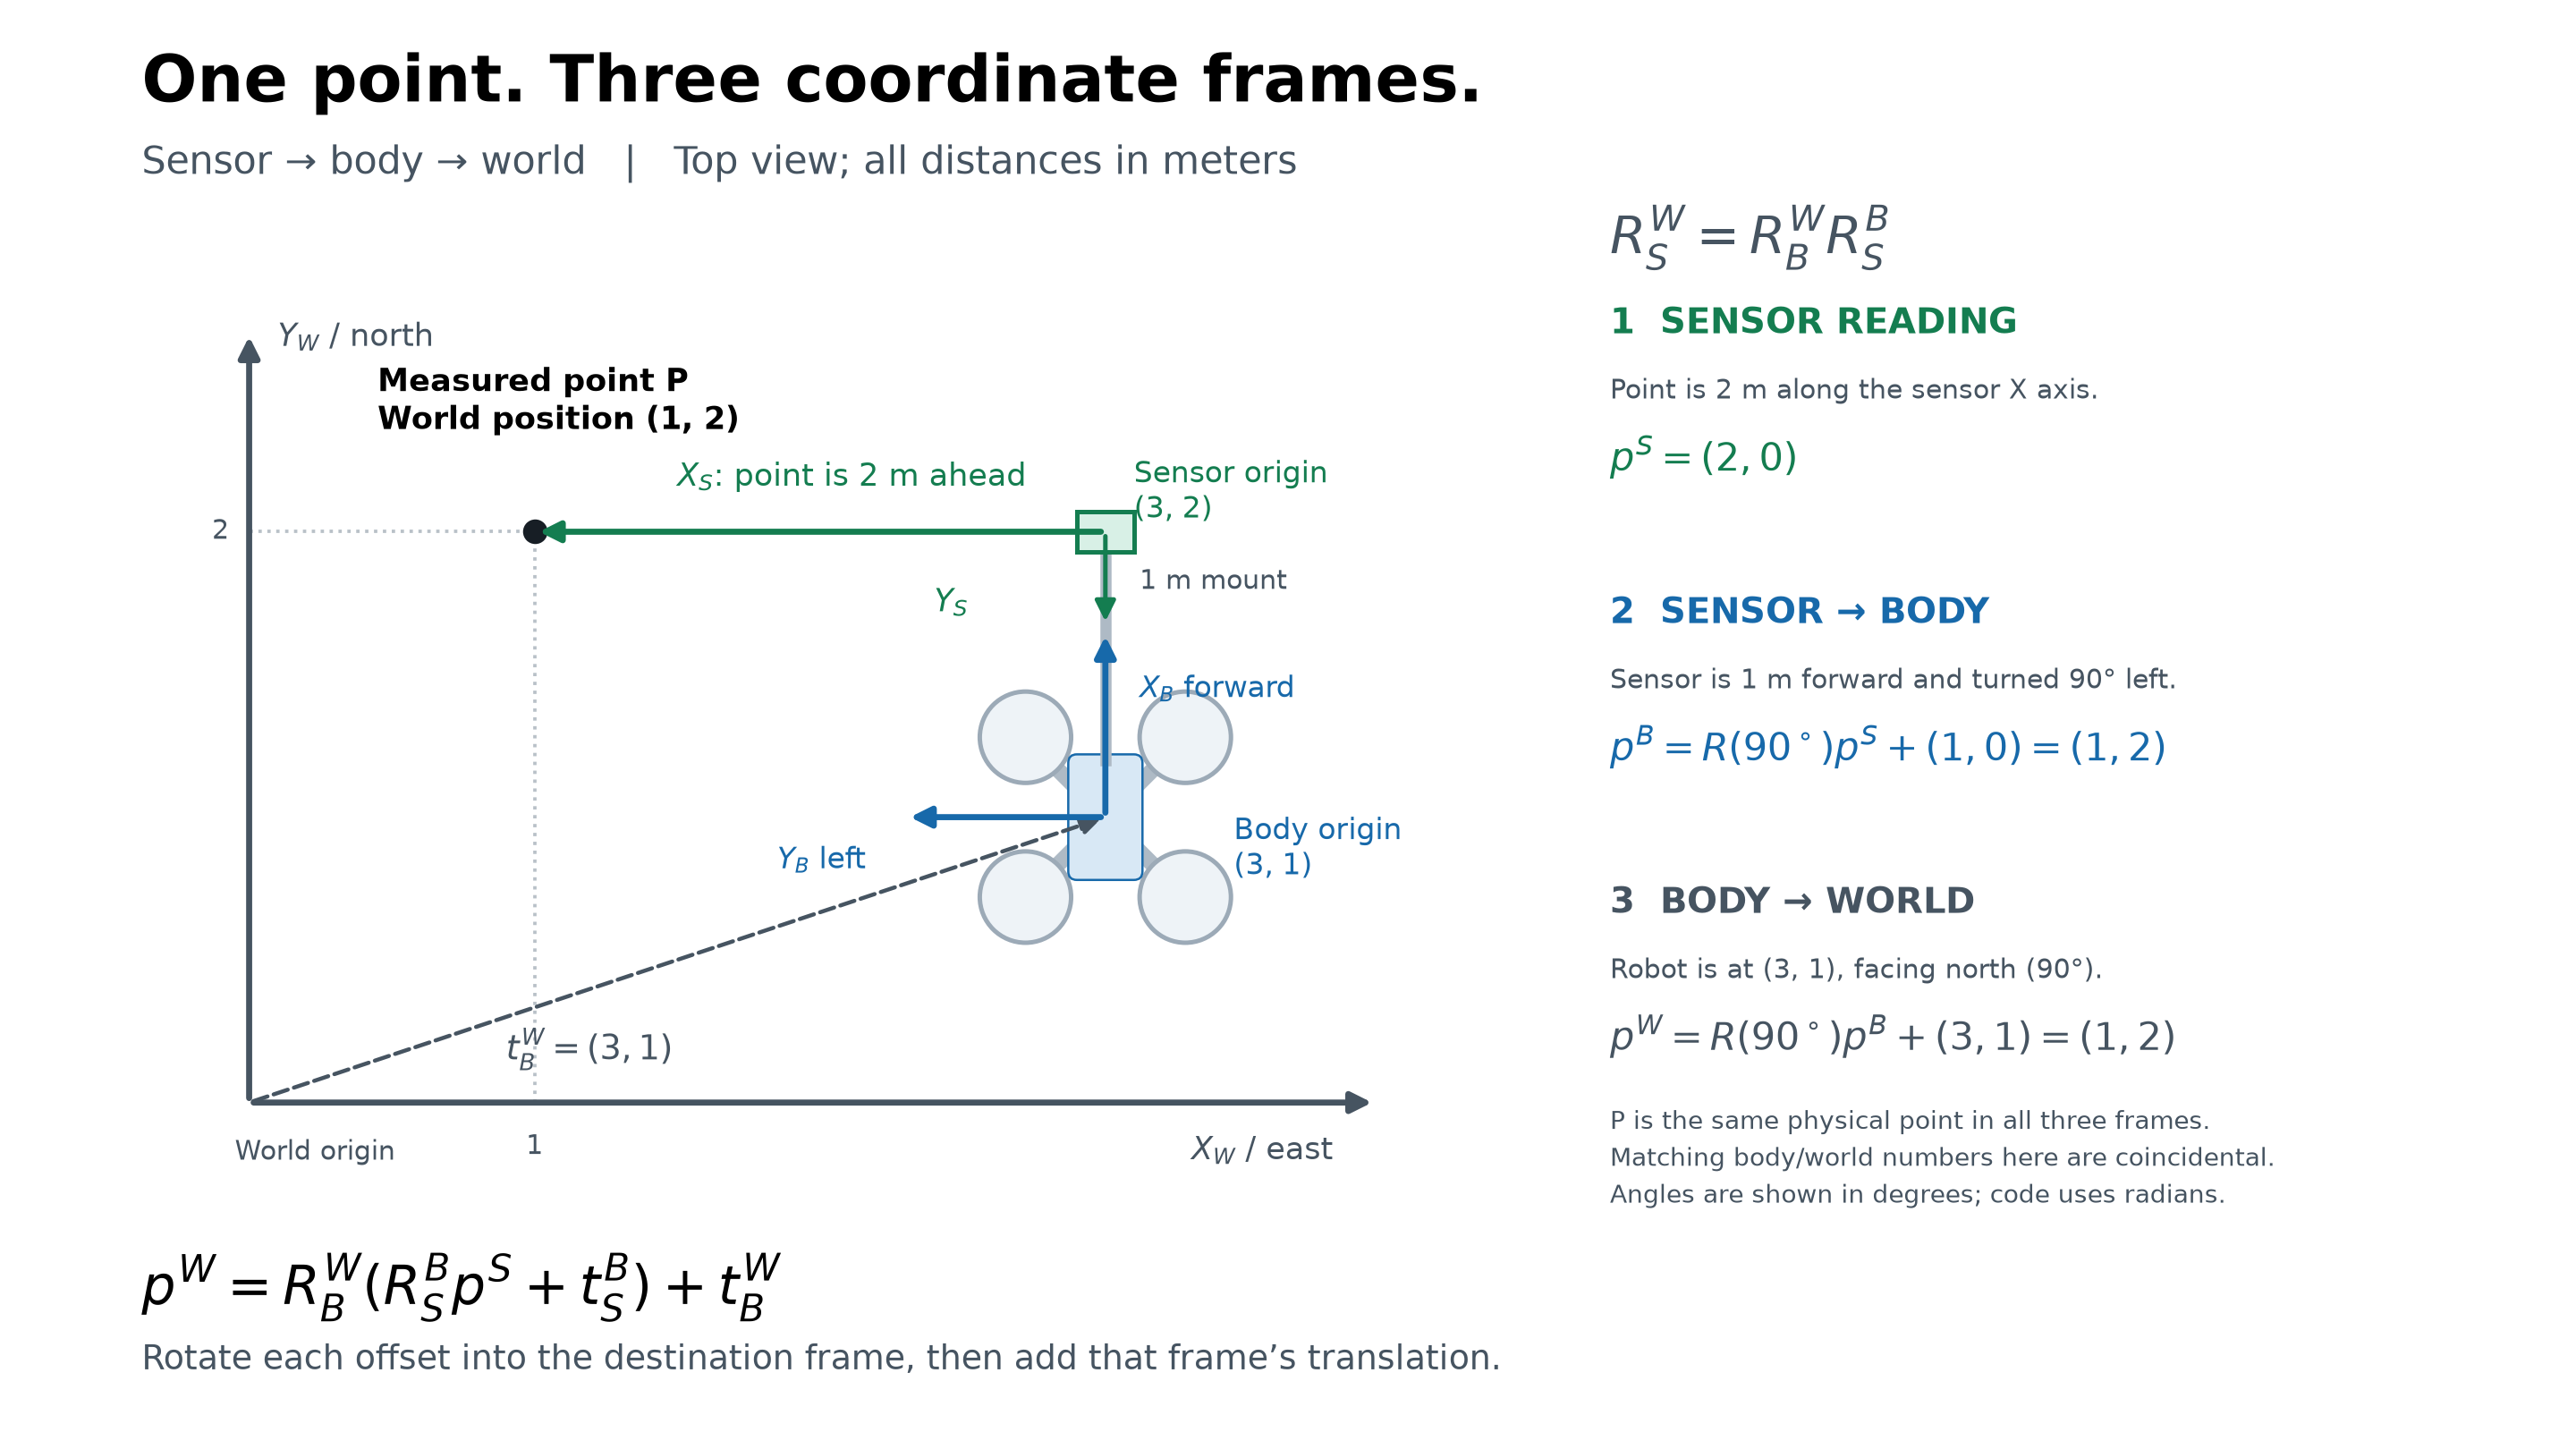

For this example:

- Robot: world position (3, 1), yaw 90°.
- Sensor: mounted 1 m forward, so $t^{B}_{S}=[1,0]^T$; rotated 90° relative to the body, so it faces west in the world.
- Measured point: $p^{S}=[2,0]^T$ m.

$$p^{B}=R(\pi/2)\begin{bmatrix}2\\0\end{bmatrix}+\begin{bmatrix}1\\0\end{bmatrix}
=\begin{bmatrix}1\\2\end{bmatrix},$$

$$p^{W}=R(\pi/2)\begin{bmatrix}1\\2\end{bmatrix}+\begin{bmatrix}3\\1\end{bmatrix}
=\begin{bmatrix}1\\2\end{bmatrix}.$$

The two coordinate pairs happen to match here; they refer to different origins and axes. The sensor origin is at world (3, 2), and the point is 2 m west of it, at (1, 2).

**Predict:** if the sensor faces body-forward instead, where does the same sensor reading place the point? This is a different sensor orientation, so it represents a different physical point. The sensor-to-world rotation changes, but the mounting offset does not.

This extension is optional; the independent challenge still uses one body-to-world rotation.

## 25–35 min: conditionals and for loops

Comparisons return Boolean values. `if` tests a condition, `elif` tests another, and `else` handles the remaining case. Indent each branch. `==` compares; `=` assigns.

Predict the message. Change the distance to trigger each branch.

In [62]:
distance_to_target = 0.08
if distance_to_target <= 0.1:
    print("Waypoint reached")
elif distance_to_target <= 1.0:
    print("Approaching waypoint")
else:
    print("Waypoint far away")

Waypoint reached


A `for` loop visits each item in a sequence. `append` adds a result to a list. Predict how many vectors will be stored, then add 360° to the headings.

In [63]:
angles_deg = [0, 45, 90, 135, 180, 270]
rotated_points = []
for angle in angles_deg:
    rotated = rotation_matrix(np.deg2rad(angle)) @ point_body
    rotated_points.append(rotated)
print(len(rotated_points))

6


`range(3)` gives 0, 1, 2; the endpoint is excluded. Indices let you read matching entries from two sequences. Predict the last index below.

In [64]:
for index in range(len(angles_deg)):
    print(index, angles_deg[index], rotated_points[index])

0 0 [2. 0.]
1 45 [1.41421356 1.41421356]
2 90 [1.2246468e-16 2.0000000e+00]
3 135 [-1.41421356  1.41421356]
4 180 [-2.0000000e+00  2.4492936e-16]
5 270 [-3.6739404e-16 -2.0000000e+00]


**Exercise (2 minutes):** loop over 0°, 90°, 180°, and 270°. Print vectors whose world Y coordinate exceeds 1 m. Explain which headings pass.

In [65]:
# Write your loop and conditional here.

## 35–45 min: while loops

A `while` loop repeats while its condition is true. Predict when this clock stops. Without the time update, it would run forever; use Interrupt to stop it.

Decimal timesteps accumulate rounding error. Use an integer step count when you need an exact number of updates.

In [66]:
time = 0.0
dt = 0.1
while time < 2.0:
    print(round(time, 2))
    time += dt

0.0
0.1
0.2
0.3
0.4
0.5
0.6
0.7
0.8
0.9
1.0
1.1
1.2
1.3
1.4
1.5
1.6
1.7
1.8
1.9


The vehicle rotates in place at 0.2 rad/s. Predict its final yaw. Change `dt` and the step count while keeping the total duration unchanged.

In [67]:
yaw = 0.0
omega = 0.2
dt = 0.1
for step in range(20):
    yaw = yaw + omega * dt
print(yaw, "rad")

0.40000000000000024 rad


**Exercise (2 minutes):** update yaw in a while loop until it reaches 0.5 rad or 100 updates have run. Why must both yaw and the counter change?

In [68]:
# Write your bounded while loop here.

## 45–50 min: plotting and debugging

Predict the path of a fixed-length point as yaw changes. Use equal axis scales so a circle appears circular.

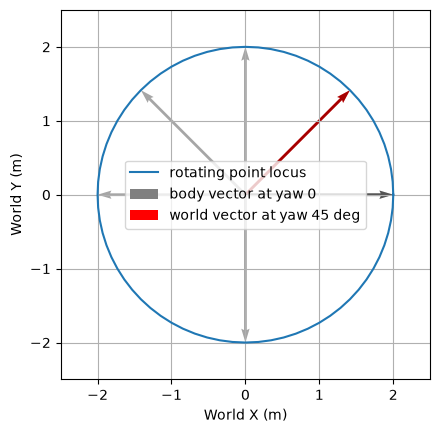

In [69]:
circle_points = []
for angle in range(0, 361, 5):
    circle_points.append(rotation_matrix(np.deg2rad(angle)) @ point_body)
circle_points = np.array(circle_points)
points = np.array(rotated_points)
fig, ax = plt.subplots()
ax.plot(circle_points[:, 0], circle_points[:, 1], label="rotating point locus")
ax.quiver(0, 0, *point_body, angles="xy", scale_units="xy", scale=1,
          color="gray", label="body vector at yaw 0")
ax.quiver(0, 0, *point_world, angles="xy", scale_units="xy", scale=1,
          color="red", label="world vector at yaw 45 deg")
ax.quiver(np.zeros(len(points)), np.zeros(len(points)), points[:, 0], points[:, 1],
          angles="xy", scale_units="xy", scale=1, alpha=0.35)
ax.set(xlabel="World X (m)", ylabel="World Y (m)", xlim=(-2.5, 2.5), ylim=(-2.5, 2.5))
ax.set_aspect("equal")
ax.grid(True)
ax.legend()
plt.show()

### Debugging

Read the traceback's last line for the exception and message. Find the line in your code, inspect values and shapes, fix the cause, and rerun.

The next cell catches a deliberate error so Run All can finish. Predict the error, then fix the index. You do not need to write `try`/`except` for the challenge.

In [70]:
import traceback
try:
    print(point_body[2])  # Deliberate IndexError: valid indices are 0 and 1.
except IndexError:
    traceback.print_exc(limit=1)

Traceback (most recent call last):
  File "/tmp/ipykernel_16936/2812875765.py", line 3, in <module>
    print(point_body[2])  # Deliberate IndexError: valid indices are 0 and 1.
          ~~~~~~~~~~^^^
IndexError: index 2 is out of bounds for axis 0 with size 2


Check these errors in a scratch cell:

- `rotation_matrix(90) @ point_body`: wrong units; it runs but gives the wrong result.
- `Rotation_matrix(0)`: wrong capitalization causes `NameError`.
- `print(angle_rad)`: the variable is local to a function; expect `NameError`.
- `np.array([1, 2, 3]) @ point_body`: incompatible shapes cause `ValueError`.
- Missing colon or wrong indentation: check the `SyntaxError` or `IndentationError` location.

Restart and run all cells after changing their execution order.

## 50–75 min: independent challenge

Use notes, the quick reference, or official Python/NumPy documentation. Disable AI chat and completions.

The quadcopter stays at world (0, 0). A point is 2 m forward in its body frame.

1. Write a function that accepts degrees, converts to radians, builds the rotation matrix, and returns the world point. Build the matrix yourself rather than calling the earlier helper.
2. Use a `for` loop to evaluate the supplied headings and store the points.
3. Use `if` to report whether rotation preserves length.
4. Plot the points with equal axis scales.

Check 0° → [2, 0], 90° → approximately [0, 2], and 180° → approximately [-2, 0]. All points should be 2 m from the origin. Use approximate comparisons.

In [71]:
def point_at_heading(angle_deg):
    # TODO: convert degrees to radians.
    # TODO: construct the 2x2 rotation matrix.
    # TODO: transform [2.0, 0.0] and return the resulting array.
    pass

challenge_angles = [0, 45, 90, 135, 180, 270, 360]
challenge_points = []
# TODO: loop through headings and append each returned point.
# TODO: check length with an if statement and print a useful message.
# TODO: plot X versus Y with labels and equal aspect ratio.

<details><summary>Hint: conversion</summary>
Use `np.deg2rad(angle_deg)`. Build the matrix from two row lists. Use `append` to collect points.
</details>

<details><summary>Hint: checks</summary>
Use `np.linalg.norm` for length and `np.isclose` or `np.allclose` for comparisons. Convert collected points to an array to select X and Y columns.
</details>

<details><summary>Hint: geometry</summary>
The matrix's first column is the rotated forward unit vector. Positive yaw turns it toward world Y.
</details>

**Optional:** move the robot center to (3, −1) m. Plot the point and explain why you rotate before translating. Check that the radius stays 2 m.